# Bloque 1 · Vivienda española con perspectiva histórica

Compra desde **1995**, alquiler general desde **2011**, municipios desde **2005**.
Los cálculos y el código de las primeras gráficas están visibles en este notebook.
La comparación reciente 2021–2024 se conserva en `01_prices.ipynb`.

**Pregunta política:** ¿qué partes de la subida pertenecen a tendencias largas y a qué
ciclos se enfrentó cada gobierno? Las franjas son contexto; no estiman causalidad.

In [1]:
from pathlib import Path
import sys
import io

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, SVG

ROOT = Path.cwd()
if not (ROOT / "data/snapshots/block01").exists():
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
SNAPSHOT = ROOT / "data/snapshots/block01"

def read_csv(name):
    return pd.read_csv(SNAPSHOT / name, dtype={"code": str, "muniCode": str})

valuations = read_csv("valuations.csv")
ipv = read_csv("purchase_index.csv")
ipva = read_csv("rent_general_history.csv")
cpi_data = read_csv("cpi.csv")
governments = read_csv("governments.csv")
municipal = read_csv("municipal_purchase.csv")

purchase_m2 = valuations.query('level == "national"').set_index("year").value.sort_index()
purchase_index = ipv.query('code == "00"').set_index("year").value.sort_index()
rent_index = ipva.query('code == "00"').set_index("year").value.sort_index()
cpi = cpi_data.query('code == "00"').set_index("year").value.sort_index()
coverage = pd.DataFrame([
    {"serie": name, "primer_año": int(s.index.min()), "último_año": int(s.index.max()),
     "años_observados": len(s)}
    for name, s in [("Compra: tasación €/m²", purchase_m2), ("Compra: IPV", purchase_index),
                    ("Alquiler: IPVA", rent_index), ("IPC", cpi)]
])
display(coverage)

,serie,primer_año,último_año,años_observados
0,Compra: tasación €/m²,1995,2025,31
1,Compra: IPV,2007,2025,19
2,Alquiler: IPVA,2011,2024,14
3,IPC,2002,2025,24


## 1. El ciclo completo de compra y alquiler

Tasación y compraventa efectiva miden conceptos diferentes. El alquiler nacional es
un índice fiscal; no se reconstruye un precio nacional en euros promediando medianas.
El código dibuja las observaciones originales sin rellenar años ausentes.

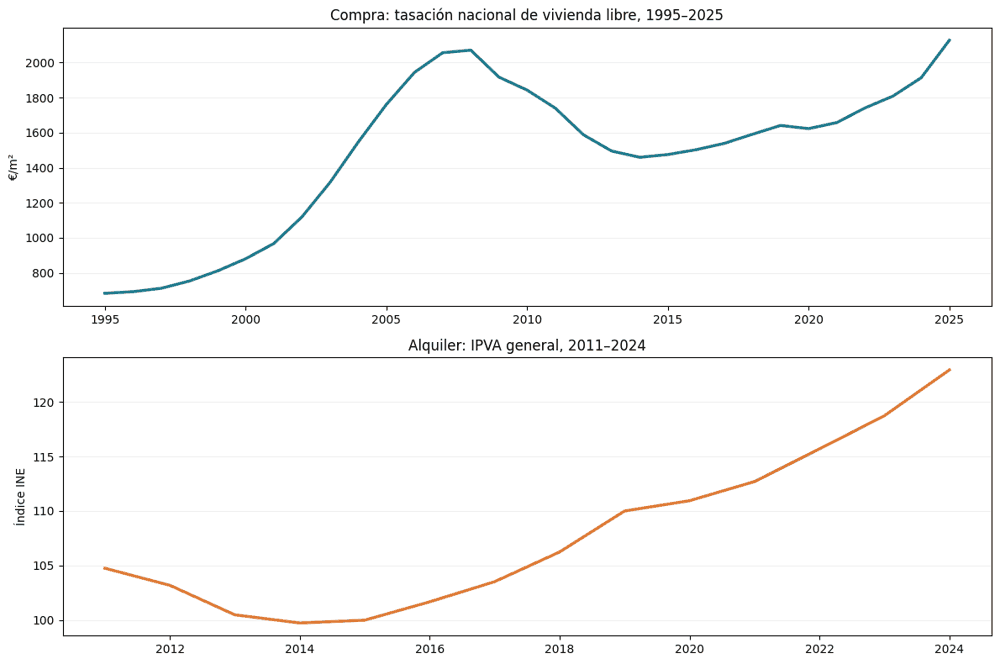

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].plot(purchase_m2.index, purchase_m2, color="#207b8e", linewidth=2.5)
axes[0].set(title="Compra: tasación nacional de vivienda libre, 1995–2025", ylabel="€/m²")
axes[1].plot(rent_index.index, rent_index, color="#de7b36", linewidth=2.5)
axes[1].set(title="Alquiler: IPVA general, 2011–2024", ylabel="Índice INE")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)

## 2. Comparar en los mismos años: nominal y real

La intersección observada es **2011–2024**. Rebasamos a 2011 = 100 y dividimos por
el cambio del IPC. Un cambio real de precios no mide esfuerzo del hogar ni ingresos.

**Escalas comparables:** ambos paneles usan el mismo eje vertical de 70 a 135,
las mismas marcas y fechas. La línea de 100 representa 2011; las etiquetas muestran
la variación acumulada desde ese año.

,Cambio nominal (%),Cambio real (%)
Compra IPV,27.91,0.37
Alquiler IPVA,17.33,-7.93


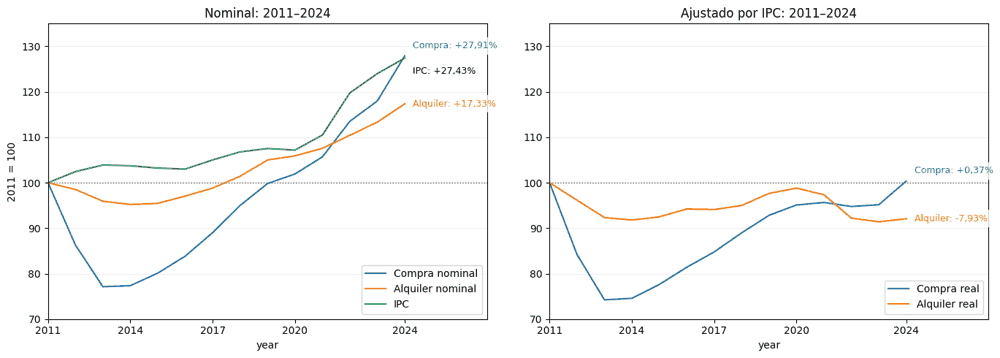

In [3]:
years = sorted(set(purchase_index.index) & set(rent_index.index) & set(cpi.index))
first, last = years[0], years[-1]
comparison = pd.DataFrame(index=years)
comparison.index.name = "year"
comparison["Compra nominal"] = purchase_index.loc[years] / purchase_index.loc[first] * 100
comparison["Alquiler nominal"] = rent_index.loc[years] / rent_index.loc[first] * 100
comparison["IPC"] = cpi.loc[years] / cpi.loc[first] * 100
comparison["Compra real"] = comparison["Compra nominal"] / (comparison["IPC"] / 100)
comparison["Alquiler real"] = comparison["Alquiler nominal"] / (comparison["IPC"] / 100)
results = pd.DataFrame({
    "Cambio nominal (%)": [comparison["Compra nominal"].loc[last] - 100,
                            comparison["Alquiler nominal"].loc[last] - 100],
    "Cambio real (%)": [comparison["Compra real"].loc[last] - 100,
                         comparison["Alquiler real"].loc[last] - 100],
}, index=["Compra IPV", "Alquiler IPVA"])
display(results.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
comparison[["Compra nominal", "Alquiler nominal", "IPC"]].plot(ax=axes[0])
comparison[["Compra real", "Alquiler real"]].plot(ax=axes[1])
for ax, title in zip(axes, ["Nominal", "Ajustado por IPC"]):
    ax.set(title=f"{title}: {first}–{last}", ylabel=f"{first} = 100")
    ax.set_ylim(70, 135)
    ax.set_yticks(range(70, 136, 10))
    ax.tick_params(axis="y", labelleft=True)
    ax.set_xlim(first, last + 3)
    ax.set_xticks([first, 2014, 2017, 2020, last])
    ax.axhline(100, color="#555", linestyle=":", linewidth=1)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="lower right")
for ax, suffix in zip(axes, ["nominal", "real"]):
    for label, color, offset in [("Compra", "#1f77b4", 10), ("Alquiler", "#ff7f0e", 0)]:
        value = comparison.loc[last, f"{label} {suffix}"]
        pct = f"{value - 100:+.2f}%".replace(".", ",")
        ax.annotate(f"{label}: {pct}", (last, value), xytext=(8, offset),
                    textcoords="offset points", color=color, fontsize=9, va="center",
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
inflation = comparison.loc[last, "IPC"]
pct = f"{inflation - 100:+.2f}%".replace(".", ",")
axes[0].annotate(f"IPC: {pct}", (last, inflation), xytext=(8, -13),
                 textcoords="offset points", fontsize=9, va="center",
                 bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
fig.tight_layout()
display(fig)
plt.close(fig)

## 3. Máximo precrisis, mínimo posterior y recuperación

Buscamos extremos dentro de ventanas explícitas: máximo **1995–2008**, mínimo
**2009–2015**. El mínimo de la tasación no tiene por qué coincidir con el del IPV.
El IPC de este snapshot empieza en 2002; no damos cambios reales desde 1995.

,Año,Tasación €/m²
Máximo precrisis (ventana),2008,2071.07
Mínimo postcrisis (ventana),2014,1459.40
Último año completo,2025,2127.57


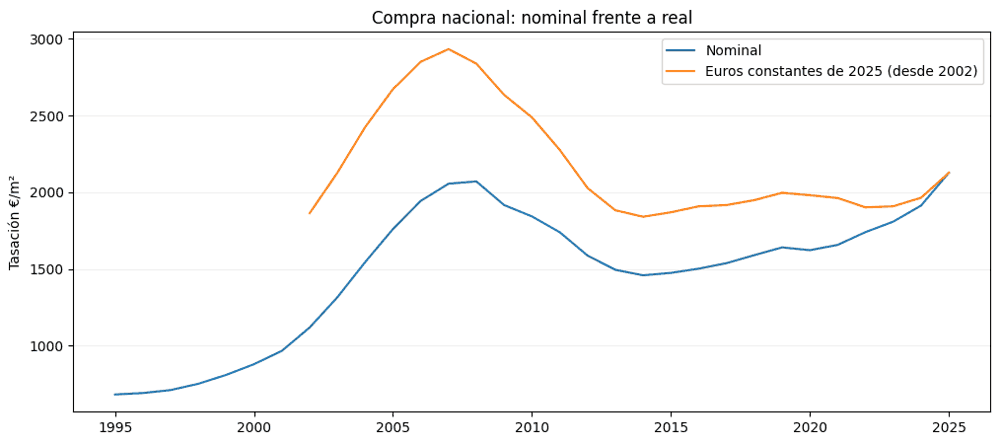

Caída máximo–mínimo: -29.53%
Recuperación mínimo–último: 45.78%


In [4]:
peak_year = int(purchase_m2.loc[1995:2008].idxmax())
trough_year = int(purchase_m2.loc[2009:2015].idxmin())
latest_year = int(purchase_m2.index.max())
cycle = pd.DataFrame({
    "Año": [peak_year, trough_year, latest_year],
    "Tasación €/m²": [purchase_m2.loc[y] for y in [peak_year, trough_year, latest_year]],
}, index=["Máximo precrisis (ventana)", "Mínimo postcrisis (ventana)", "Último año completo"])
display(cycle.round(2))
print(f"Caída máximo–mínimo: {(purchase_m2.loc[trough_year] / purchase_m2.loc[peak_year] - 1) * 100:.2f}%")
print(f"Recuperación mínimo–último: {(purchase_m2.loc[latest_year] / purchase_m2.loc[trough_year] - 1) * 100:.2f}%")

# Euros constantes de 2025; años sin IPC quedan ausentes.
real_purchase_m2 = purchase_m2 * cpi.loc[2025] / cpi.reindex(purchase_m2.index)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(purchase_m2.index, purchase_m2, label="Nominal")
ax.plot(real_purchase_m2.index, real_purchase_m2, label="Euros constantes de 2025 (desde 2002)")
ax.set(title="Compra nacional: nominal frente a real", ylabel="Tasación €/m²")
ax.legend()
ax.grid(axis="y", alpha=0.2)
display(fig)
plt.close(fig)

## 4. Regenerar el informe, ocho figuras y las tablas históricas

El módulo publicado incluye el código de mapas, paneles políticos y muestras fijas.
Los CSV contienen la cobertura de cada territorio y los cálculos completos, no solo una imagen.

In [5]:
from spain_housing.price_history import run_history
figures, findings = run_history(ROOT)
TABLES = ROOT / "reports/tables/history"
print(f"{len(figures)} figuras históricas generadas; tablas en {TABLES.relative_to(ROOT)}")
display(pd.read_csv(TABLES / "region_purchase_history.csv").round(2))

,code,name,first_year,last_year,observed_years,missing_years,first_value,last_value,nominal_change_pct,real_first_year,real_last_year,real_change_pct,precrisis_peak_year,precrisis_peak_value,postcrisis_trough_year,postcrisis_trough_value,peak_to_trough_pct,trough_to_latest_pct,peak_to_latest_pct
0,1,Andalucía,1995,2025,31,0,509.52,1774.75,248.31,2002,2025,18.97,2008,1781.78,2014,1208.08,-32.20,46.91,-0.39
1,2,Aragón,1995,2025,31,0,582.95,1567.08,168.82,2002,2025,-12.07,2007,1914.92,2014,1167.03,-39.06,34.28,-18.17
2,3,Asturias,1995,2025,31,0,643.33,1600.75,148.82,2002,2025,-8.16,2008,1769.80,2015,1270.55,-28.21,25.99,-9.55
3,4,Illes Balears,1995,2025,31,0,592.10,3609.12,509.55,2002,2025,48.73,2008,2409.52,2012,1839.58,-23.65,96.19,49.79
4,5,Canarias,1995,2025,31,0,593.02,2044.05,244.68,2002,2025,4.50,2007,1795.88,2014,1272.85,-29.12,60.59,13.82
5,6,Cantabria,1995,2025,31,0,737.82,1885.58,155.56,2002,2025,-7.69,2007,2039.25,2015,1477.90,-27.53,27.58,-7.54
6,7,Castilla y León,1995,2025,31,0,631.30,1187.65,88.13,2002,2025,-23.93,2007,1501.60,2015,1057.55,-29.57,12.30,-20.91
7,8,Castilla-La Mancha,1995,2025,31,0,505.32,1073.88,112.51,2002,2025,-15.96,2007,1424.12,2015,885.60,-37.81,21.26,-24.59
8,9,Cataluña,1995,2025,31,0,746.08,2535.72,239.88,2002,2025,12.33,2008,2463.35,2014,1662.60,-32.51,52.52,2.94
9,10,Comunitat Valenciana,1995,2025,31,0,484.25,1707.82,252.67,2002,2025,11.21,2008,1670.45,2014,1122.25,-32.82,52.18,2.24


8 figuras históricas generadas; tablas en reports/tables/history


## 5. Gobierno nacional y comunidades desde 1995

Las fechas proceden del Senado y del registro nacional. Las tablas comparan años
completos dentro de cada presidencia, excluyen años de transición y muestran cambios
acumulados y anualizados. Duraciones y coyunturas difieren; no es una clasificación causal.

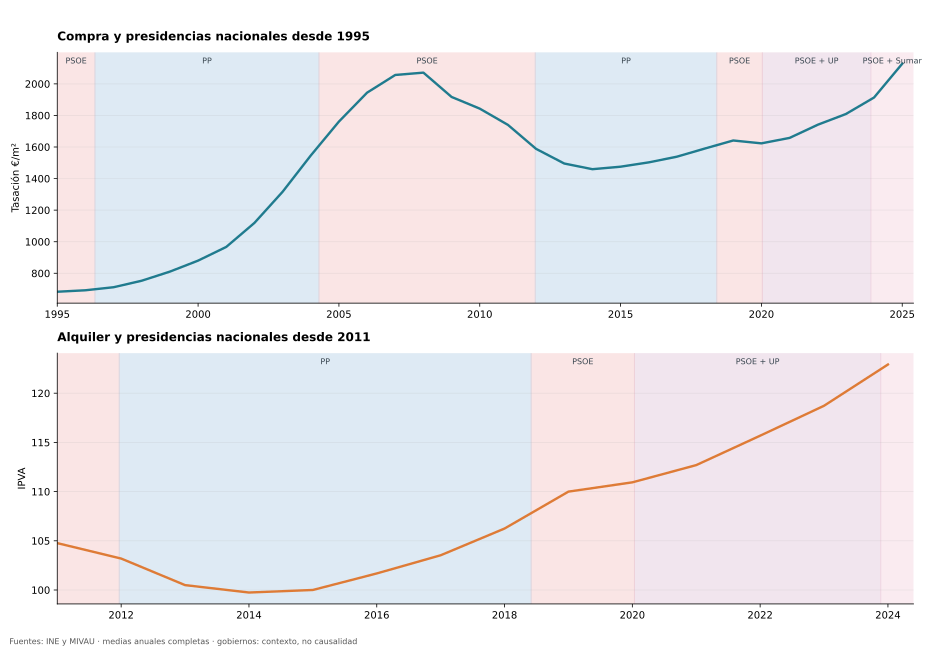

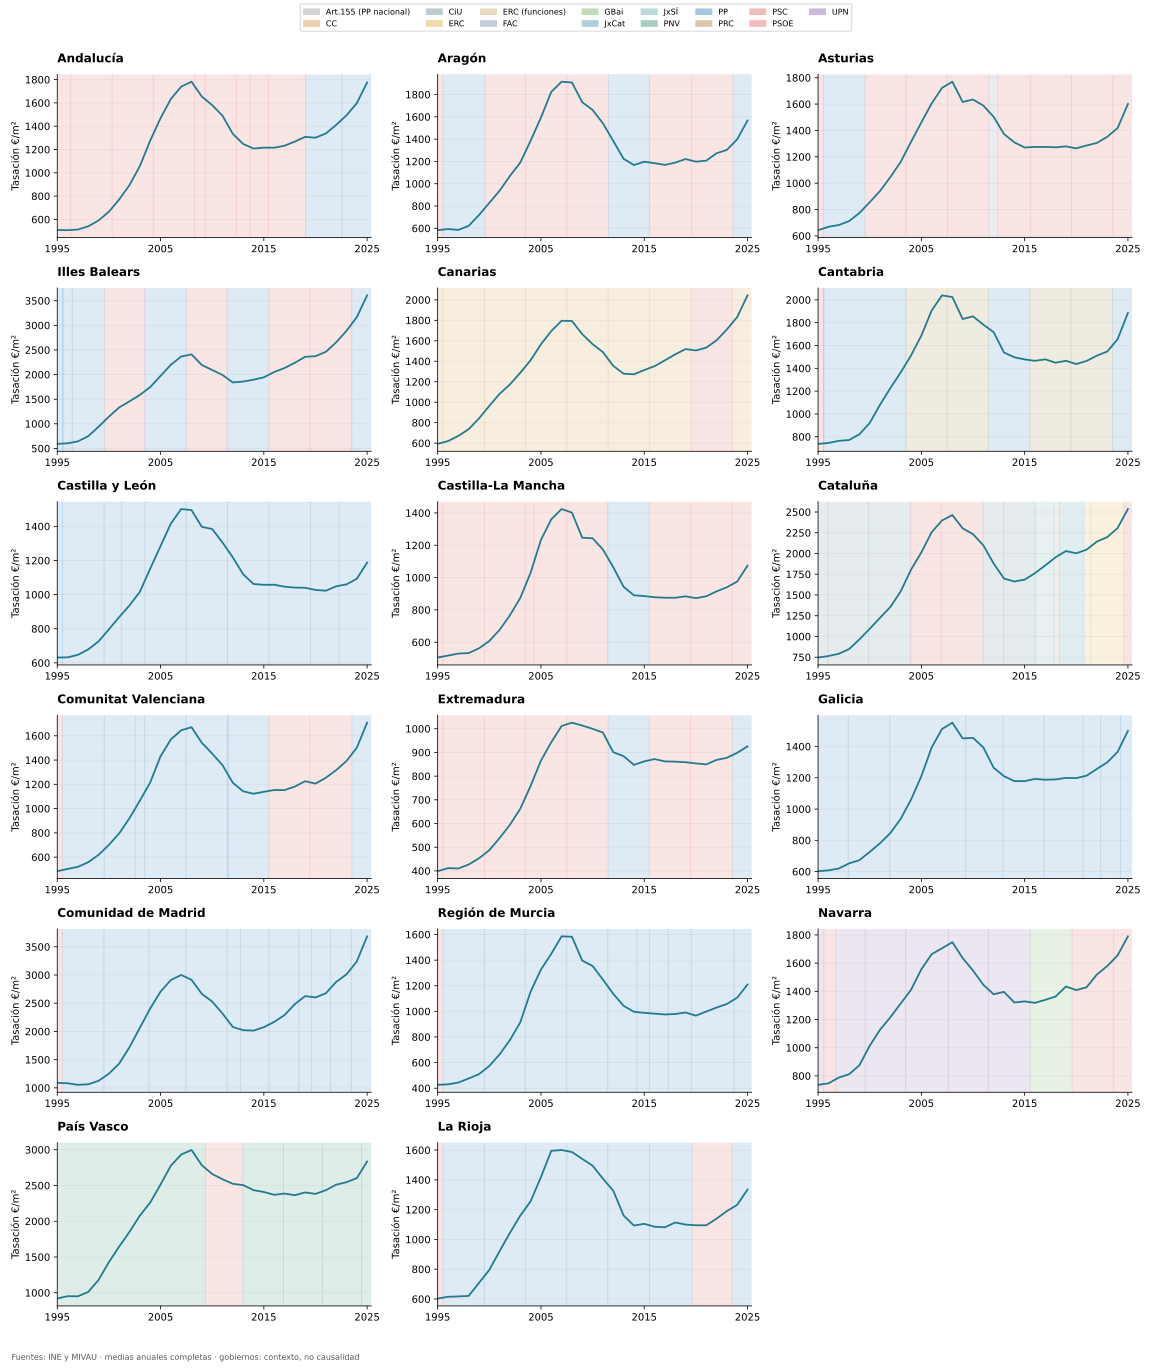

,metric,code,name,leader,party,start,end,observed_complete_years,first_year,last_year,nominal_change_pct,annualised_pct,real_change_pct
7,rent_ipva,0,España,Felipe González,PSOE,1993-07-09,1996-05-04,0,NaN,NaN,NaN,NaN,NaN
8,rent_ipva,0,España,José María Aznar,PP,1996-05-04,2004-04-17,0,NaN,NaN,NaN,NaN,NaN
9,rent_ipva,0,España,José Luis Rodríguez Zapatero,PSOE,2004-04-17,2011-12-21,0,NaN,NaN,NaN,NaN,NaN
10,rent_ipva,0,España,Mariano Rajoy,PP,2011-12-21,2018-06-02,6,2012.0,2017.0,0.32,0.06,-2.13
11,rent_ipva,0,España,Pedro Sánchez,PSOE,2018-06-02,2020-01-13,1,NaN,NaN,NaN,NaN,NaN
12,rent_ipva,0,España,Pedro Sánchez,PSOE + UP,2020-01-13,2023-11-21,2,2021.0,2022.0,2.65,2.65,-5.29
13,rent_ipva,0,España,Pedro Sánchez,PSOE + Sumar,2023-11-21,NaN,1,NaN,NaN,NaN,NaN,NaN


In [6]:
display(SVG(filename=str(ROOT / "reports/figures/history/02_national_governments.svg")))
display(SVG(filename=str(ROOT / "reports/figures/history/07_regional_governments_1995.svg")))
mandates = pd.read_csv(TABLES / "government_history.csv")
display(mandates[mandates.metric.isin(["rent_ipva"])].round(2))

## 6. Mapas históricos de comunidades y provincias

Mismos extremos en cada mapa: **1995–2025 nominal** y **2002–2025 real**.
Contornos generalizados; se omiten islotes menores de aproximadamente 1 km².
Las tablas conservan todos los territorios y especifican cobertura.

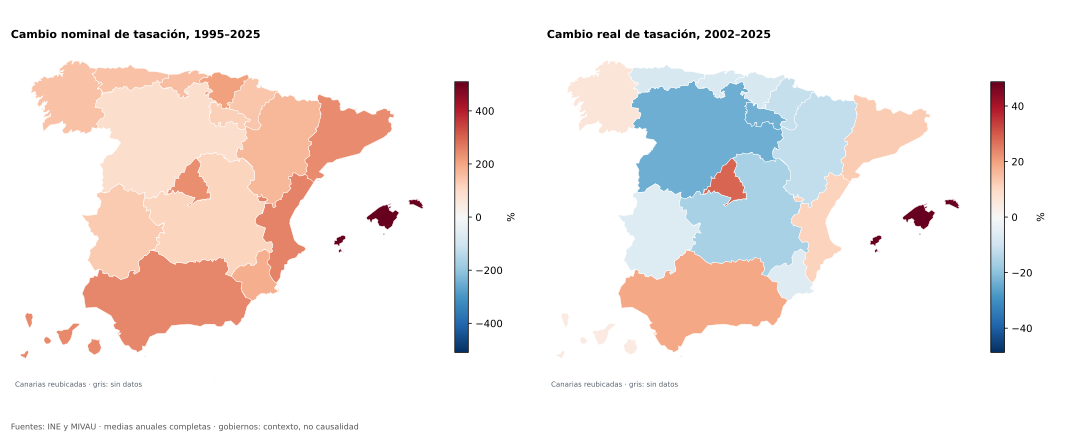

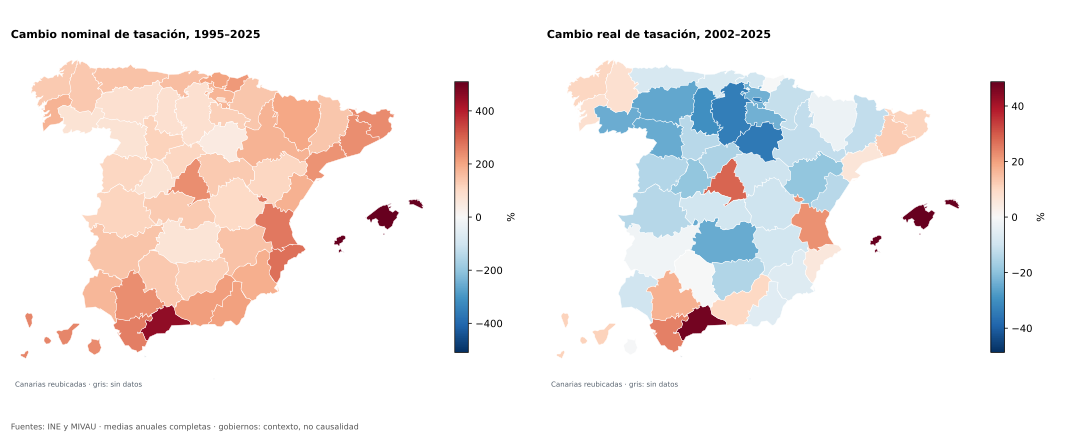

,code,name,first_year,last_year,observed_years,missing_years,first_value,last_value,nominal_change_pct,real_first_year,real_last_year,real_change_pct,precrisis_peak_year,precrisis_peak_value,postcrisis_trough_year,postcrisis_trough_value,peak_to_trough_pct,trough_to_latest_pct,peak_to_latest_pct
0,1,Araba/Álava,1995,2025,31,0,860.80,2336.18,171.40,2002,2025,-23.52,2006,2517.30,2015,1976.25,-21.49,18.21,-7.20
1,2,Albacete,1995,2025,31,0,438.95,1102.18,151.09,2002,2025,-9.19,2007,1343.20,2014,934.62,-30.42,17.93,-17.94
2,3,Alicante/Alacant,1995,2025,31,0,475.88,1806.40,279.60,2002,2025,5.61,2007,1736.30,2014,1207.78,-30.44,49.56,4.04
3,4,Almería,1995,2025,31,0,433.80,1342.48,209.47,2002,2025,-6.03,2008,1674.08,2015,1089.03,-34.95,23.27,-19.81
4,5,Ávila,1995,2025,31,0,593.67,1040.90,75.33,2002,2025,-19.14,2008,1410.90,2015,839.60,-40.49,23.98,-26.22
5,6,Badajoz,1995,2025,31,0,388.72,948.05,143.89,2002,2025,-1.82,2008,1050.18,2014,854.70,-18.61,10.92,-9.72
6,7,"Balears, Illes",1995,2025,31,0,592.10,3609.12,509.55,2002,2025,48.73,2008,2409.52,2012,1839.58,-23.65,96.19,49.79
7,8,Barcelona,1995,2025,31,0,878.52,2962.45,237.21,2002,2025,12.44,2008,2770.50,2014,1884.52,-31.98,57.20,6.93
8,9,Burgos,1995,2025,31,0,719.65,1311.60,82.26,2002,2025,-33.77,2007,1780.95,2014,1145.22,-35.70,14.53,-26.35
9,10,Cáceres,1995,2025,31,0,416.40,894.80,114.89,2002,2025,-14.00,2008,982.42,2015,828.82,-15.63,7.96,-8.92


In [7]:
display(SVG(filename=str(ROOT / "reports/figures/history/05_region_long_growth_maps.svg")))
display(SVG(filename=str(ROOT / "reports/figures/history/06_province_long_growth_maps.svg")))
display(pd.read_csv(TABLES / "province_purchase_history.csv").round(2))

## 7. Grandes ciudades, periferias, costa e interior

Compra municipal **2005–2025**, alquiler fiscal **2011–2024**. Cada curva usa una
muestra fija con observaciones en todos sus años, media no ponderada de índices
municipales. La selección de 30 casos no representa todo el mercado español.

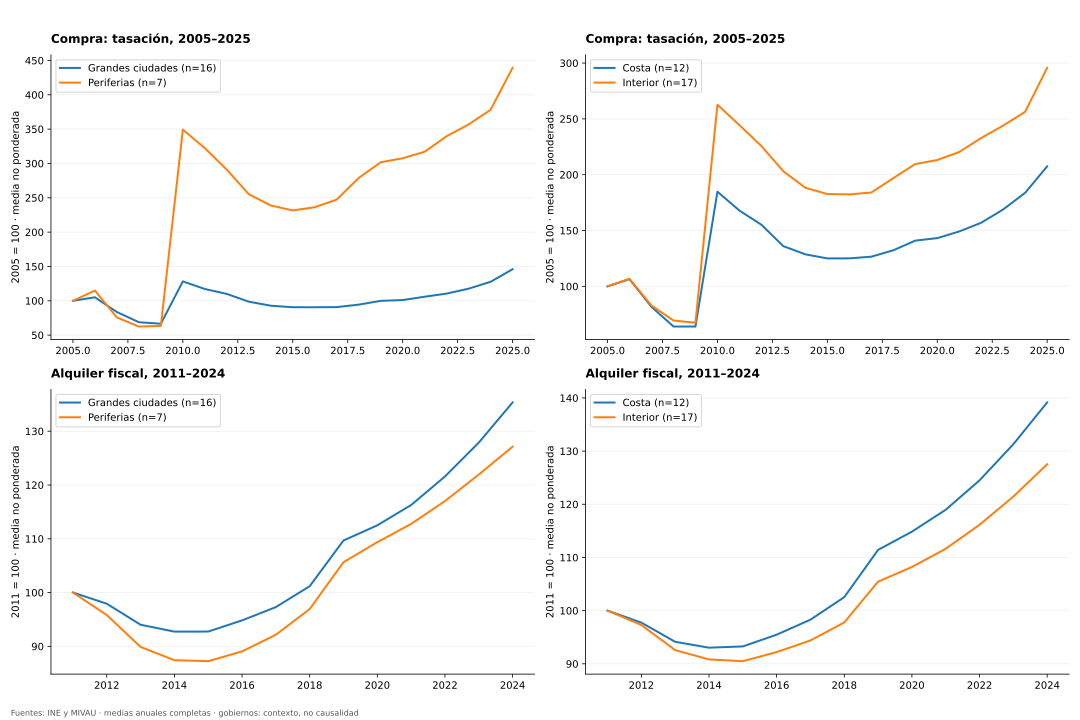

,code,name,first_year,last_year,observed_years,missing_years,first_value,last_value,nominal_change_pct,real_first_year,real_last_year,real_change_pct,precrisis_peak_year,precrisis_peak_value,postcrisis_trough_year,postcrisis_trough_value,peak_to_trough_pct,trough_to_latest_pct,peak_to_latest_pct
0,3014,Alacant/Alicante,2005,2025,21,0,1709.75,2069.35,21.03,2005,2025,-20.25,2006,2186.50,2014,1063.53,-51.36,94.57,-5.36
1,7040,Palma,2005,2025,21,0,2037.00,3424.15,68.10,2005,2025,10.76,2006,2362.75,2009,1417.50,-40.01,141.56,44.92
2,8015,Badalona,2005,2025,21,0,1300.75,2603.70,100.17,2005,2025,31.89,2006,1319.50,2009,634.50,-51.91,310.35,97.32
3,8019,Barcelona,2005,2025,21,0,5082.50,4339.92,-14.61,2005,2025,-43.74,2005,5082.50,2014,2398.43,-52.81,80.95,-14.61
4,8101,L'Hospitalet de Llobregat,2005,2025,21,0,1099.25,2812.72,155.88,2005,2025,68.59,2006,1137.50,2009,677.25,-40.46,315.32,147.27
5,8187,Sabadell,2005,2025,21,0,923.50,2254.82,144.16,2005,2025,60.87,2006,1143.50,2009,642.75,-43.79,250.81,97.19
6,8279,Terrassa,2005,2025,21,0,1199.00,2099.10,75.07,2005,2025,15.35,2006,1509.00,2009,761.50,-49.54,175.65,39.11
7,9059,Burgos,2005,2025,21,0,713.50,1755.25,146.01,2005,2025,62.09,2006,782.50,2009,550.50,-29.65,218.85,124.31
8,11012,Cádiz,2005,2025,21,0,509.50,2885.02,466.25,2005,2025,273.09,2005,509.50,2009,318.25,-37.54,806.53,466.25
9,12040,Castelló de la Plana/Castellón de la Plana,2005,2025,21,0,887.75,1338.72,50.80,2005,2025,-0.64,2006,986.50,2009,570.50,-42.17,134.66,35.70


metric                       group     
Alquiler fiscal, 2011–2024   coastal       12
                             inland        17
                             large_city    16
                             periphery      7
Compra: tasación, 2005–2025  coastal       12
                             inland        17
                             large_city    16
                             periphery      7
Name: code, dtype: int64

In [8]:
display(SVG(filename=str(ROOT / "reports/figures/history/08_city_profiles_long_history.svg")))
display(pd.read_csv(TABLES / "municipal_purchase_history.csv").round(2))
display(pd.read_csv(TABLES / "profile_fixed_samples.csv").groupby(["metric", "group"]).code.nunique())

## Lectura y siguientes preguntas

La ventana larga permite ver subidas y bajadas con gobiernos de distintos partidos.
No identifica qué parte se debe a políticas: habrá que estudiar tipos de interés,
construcción, hogares, ingresos y cambios normativos con diseños específicos.
Los contratos nuevos/existentes solo tienen desglose desde 2021; se analizan en el notebook inicial.

Fuentes y hashes: `data/snapshots/block01/source_manifest.json`.
Informe principal: `reports/block_01_price_history.md`.